In [1]:
from pathlib import Path

ROOT = Path.cwd()
DATA_DIR = ROOT / "FracAtlas"
IMAGE_DIR = DATA_DIR / "images"
ANNOTATION_DIR = DATA_DIR / "Annotations"
CSV_PATH = DATA_DIR / "dataset.csv"
COCO_PATH = ANNOTATION_DIR / "COCO JSON/COCO_fracture_masks.json"

In [3]:
import pandas as pd

df = pd.read_csv(CSV_PATH)

print("Number of CSV rows:", len(df))
print("\nColumns:")
print(df.columns.tolist())

print("\nFracture label counts:")
print(df["fractured"].value_counts(dropna=False))

print("\nFracture instance count:")
print(df["fracture_count"].sum())

df.head()

Number of CSV rows: 4083

Columns:
['image_id', 'hand', 'leg', 'hip', 'shoulder', 'mixed', 'hardware', 'multiscan', 'fractured', 'fracture_count', 'frontal', 'lateral', 'oblique']

Fracture label counts:
fractured
0    3364
1     719
Name: count, dtype: int64

Fracture instance count:
924


,image_id,hand,leg,hip,shoulder,mixed,hardware,multiscan,fractured,fracture_count,frontal,lateral,oblique
0,IMG0000000.jpg,0,1,0,0,0,0,1,0,0,1,1,0
1,IMG0000001.jpg,0,1,0,0,0,0,1,0,0,1,1,0
2,IMG0000002.jpg,0,1,0,0,0,0,1,0,0,1,1,0
3,IMG0000003.jpg,0,1,0,0,0,0,1,0,0,0,1,1
4,IMG0000004.jpg,0,1,0,0,0,0,1,0,0,0,1,1


In [4]:
import json

with open(COCO_PATH, "r", encoding="utf-8") as f:
    coco = json.load(f)

print("COCO keys:", coco.keys())
print("Annotated images:", len(coco.get("images", [])))
print("Annotations:", len(coco.get("annotations", [])))
print("Categories:", coco.get("categories", []))

print("\nFirst image:")
print(coco["images"][0])

print("\nFirst annotation:")
print({
    k: v
    for k, v in coco["annotations"][0].items()
    if k != "segmentation"
})

print("\nSegmentation format:")
print(str(coco["annotations"][0].get("segmentation"))[:500])

COCO keys: dict_keys(['info', 'images', 'annotations', 'categories'])
Annotated images: 719
Annotations: 924
Categories: [{'id': 1, 'name': 'fractured'}]

First image:
{'id': 1, 'width': 2304, 'height': 2880, 'file_name': 'IMG0000019.jpg'}

First annotation:
{'id': 0, 'iscrowd': 0, 'image_id': 1, 'category_id': 1, 'bbox': [1242.2970297029703, 929.1089108910893, 273.2673267326734, 147.3267326732672], 'area': 25033.78100186259}

Segmentation format:
[[1266.0594059405942, 1045.5445544554457, 1339.7227722772277, 1021.782178217822, 1401.5049504950496, 1052.673267326733, 1489.4257425742576, 1076.4356435643565, 1515.5643564356437, 1021.782178217822, 1449.0297029702972, 943.3663366336635, 1308.8316831683169, 929.1089108910893, 1242.2970297029703, 986.1386138613863]]


Image: IMG0000019.jpg
Image dimensions: (2304, 2880)
COCO dimensions: (2304, 2880)
Fracture annotations: 1
Mask values: [0 1]
Fracture pixels: 25125


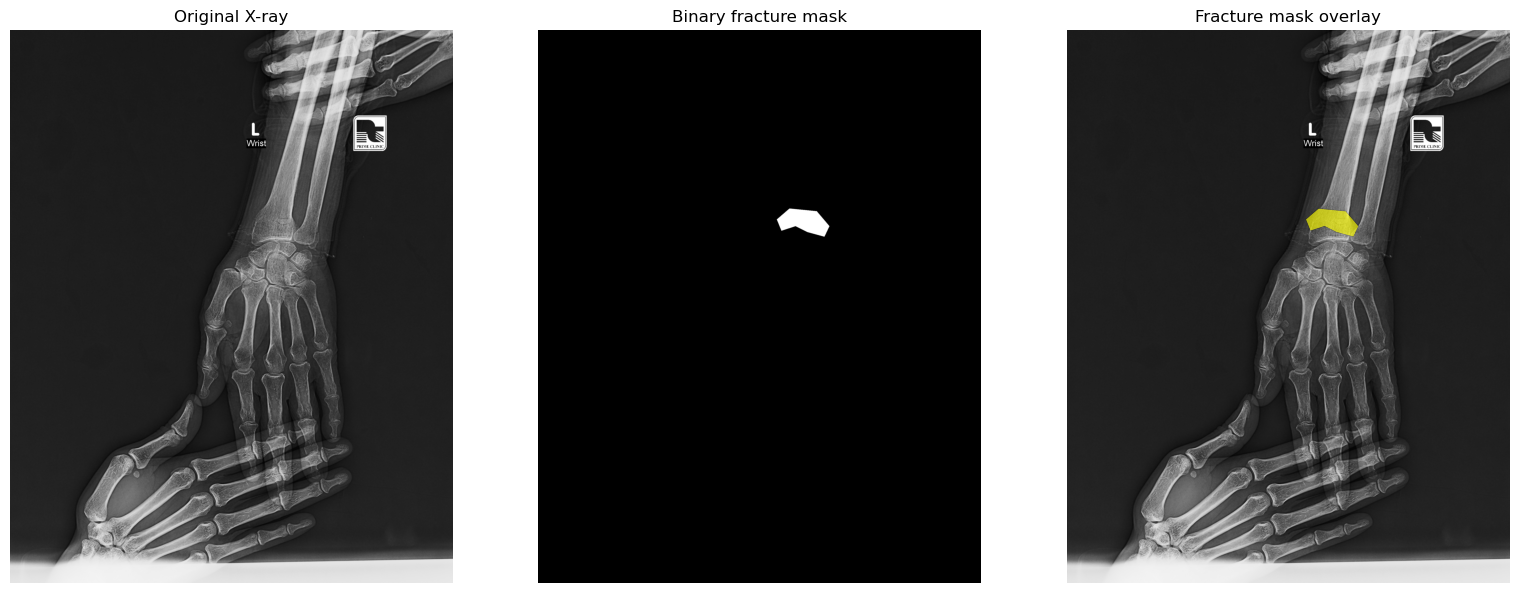

In [5]:
import json
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image, ImageDraw

# Load the COCO annotations
with open(COCO_PATH, "r", encoding="utf-8") as f:
    coco = json.load(f)

# Select the first annotated image
image_info = coco["images"][0]
image_id = image_info["id"]
image_path = IMAGE_DIR / "Fractured" / image_info["file_name"]

# Load the original X-ray
image = Image.open(image_path).convert("L")
width, height = image.size

print("Image:", image_info["file_name"])
print("Image dimensions:", image.size)
print("COCO dimensions:", (image_info["width"], image_info["height"]))

# Create an empty binary mask
mask_image = Image.new("L", (width, height), 0)
draw = ImageDraw.Draw(mask_image)

# Find all fracture annotations for this image
annotations = [
    ann for ann in coco["annotations"]
    if ann["image_id"] == image_id
]

# Fill each polygon into the mask
for ann in annotations:
    segmentation = ann["segmentation"]

    if isinstance(segmentation, list):
        for polygon in segmentation:
            points = [
                (polygon[i], polygon[i + 1])
                for i in range(0, len(polygon), 2)
            ]
            if len(points) >= 3:
                draw.polygon(points, fill=1)

mask = np.array(mask_image, dtype=np.uint8)

print("Fracture annotations:", len(annotations))
print("Mask values:", np.unique(mask))
print("Fracture pixels:", int(mask.sum()))

# Display the image, mask, and overlay
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original X-ray")

axes[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Binary fracture mask")

axes[2].imshow(image, cmap="gray")
axes[2].imshow(
    np.ma.masked_where(mask == 0, mask),
    cmap="autumn",
    alpha=0.65,
    vmin=0,
    vmax=1
)
axes[2].set_title("Fracture mask overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [10]:
PROCESSED_DIR = ROOT / "processed"
PROCESSED_IMAGE_DIR = PROCESSED_DIR / "images"
PROCESSED_MASK_DIR = PROCESSED_DIR / "masks"

PROCESSED_IMAGE_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_MASK_DIR.mkdir(parents=True, exist_ok=True)

print("Processed directory:", PROCESSED_DIR)

Processed directory: c:\Users\rylee\OneDrive\UCF\Independent Study\Bone_Fracture_Segmentation\processed


In [9]:
from pathlib import Path
import pandas as pd
import json

IMAGE_DIR = DATA_DIR / "images"
FRACTURED_DIR = IMAGE_DIR / "Fractured"
NON_FRACTURED_DIR = IMAGE_DIR / "Non_fractured"

# Index images from both folders by filename
image_paths = {}

for folder in [FRACTURED_DIR, NON_FRACTURED_DIR]:
    for path in folder.glob("*"):
        if path.is_file() and path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            image_paths[path.name] = path

print("Fractured folder exists:", FRACTURED_DIR.exists())
print("Non-fractured folder exists:", NON_FRACTURED_DIR.exists())
print("Fractured images:", sum(1 for p in image_paths.values() if p.parent == FRACTURED_DIR))
print("Non-fractured images:", sum(1 for p in image_paths.values() if p.parent == NON_FRACTURED_DIR))
print("Total unique images:", len(image_paths))
print("CSV rows:", len(df))
print("CSV image IDs found in folders:", df["image_id"].isin(image_paths).sum())
print("CSV image IDs missing from folders:", (~df["image_id"].isin(image_paths)).sum())

Fractured folder exists: True
Non-fractured folder exists: True
Fractured images: 717
Non-fractured images: 3366
Total unique images: 4083
CSV rows: 4083
CSV image IDs found in folders: 4083
CSV image IDs missing from folders: 0


In [10]:
# Load COCO annotations if not already loaded
with open(COCO_PATH, "r", encoding="utf-8") as f:
    coco = json.load(f)

coco_filenames = {img["file_name"] for img in coco["images"]}
csv_filenames = set(df["image_id"])
folder_filenames = set(image_paths)

print("COCO annotated images:", len(coco_filenames))
print("COCO images found in folders:", len(coco_filenames & folder_filenames))
print("COCO filenames missing from folders:", len(coco_filenames - folder_filenames))
print("COCO images missing from CSV:", len(coco_filenames - csv_filenames))

# Check whether every CSV fracture-positive image has a COCO annotation
fractured_csv = set(df.loc[df["fractured"] == 1, "image_id"])
print("CSV fracture-positive images:", len(fractured_csv))
print("Fracture-positive images without COCO annotations:", len(fractured_csv - coco_filenames))
print("COCO images marked non-fractured in CSV:",
      len(coco_filenames - fractured_csv))

COCO annotated images: 719
COCO images found in folders: 719
COCO filenames missing from folders: 0
COCO images missing from CSV: 0
CSV fracture-positive images: 719
Fracture-positive images without COCO annotations: 0
COCO images marked non-fractured in CSV: 0


In [11]:
from PIL import Image, ImageDraw
import numpy as np
import pandas as pd
from pathlib import Path

# Create a folder for the masks
PROCESSED_DIR = ROOT / "processed"
PROCESSED_MASK_DIR = PROCESSED_DIR / "masks"
PROCESSED_MASK_DIR.mkdir(parents=True, exist_ok=True)

# Index COCO images and annotations
coco_images = {img["file_name"]: img for img in coco["images"]}

annotations_by_image = {}
for ann in coco["annotations"]:
    annotations_by_image.setdefault(ann["image_id"], []).append(ann)

records = []
errors = []

# Generate masks only for images with COCO annotations
for filename, image_info in coco_images.items():
    image_path = image_paths.get(filename)

    if image_path is None:
        errors.append(f"Missing image: {filename}")
        continue

    with Image.open(image_path) as img:
        width, height = img.size

    if (width, height) != (image_info["width"], image_info["height"]):
        errors.append(f"Dimension mismatch: {filename}")
        continue

    mask_image = Image.new("L", (width, height), 0)
    draw = ImageDraw.Draw(mask_image)

    for ann in annotations_by_image.get(image_info["id"], []):
        for polygon in ann.get("segmentation", []):
            if len(polygon) >= 6 and len(polygon) % 2 == 0:
                points = [
                    (polygon[i], polygon[i + 1])
                    for i in range(0, len(polygon), 2)
                ]
                draw.polygon(points, fill=255)

    mask_path = PROCESSED_MASK_DIR / f"{Path(filename).stem}.png"
    mask_image.save(mask_path)

    mask_array = np.array(mask_image)

    records.append({
        "image_id": filename,
        "image_path": str(image_path),
        "mask_path": str(mask_path),
        "mask_pixels": int(np.count_nonzero(mask_array)),
    })

mask_df = pd.DataFrame(records)

print("Masks generated:", len(mask_df))
print("Errors:", len(errors))
print("Masks with fracture pixels:", (mask_df["mask_pixels"] > 0).sum())

if errors:
    print("First errors:", errors[:10])

Masks generated: 718
Errors: 1
Masks with fracture pixels: 718
First errors: ['Dimension mismatch: IMG0002628.jpg']


In [12]:
filename = "IMG0002628.jpg"

image_info = coco_images[filename]
image_path = image_paths[filename]

with Image.open(image_path) as img:
    actual_size = img.size

print("Filename:", filename)
print("Actual image size (width, height):", actual_size)
print(
    "COCO annotation size (width, height):",
    (image_info["width"], image_info["height"])
)
print("COCO image ID:", image_info["id"])

annotations = annotations_by_image.get(image_info["id"], [])
print("Number of annotations:", len(annotations))

for ann in annotations:
    print("Bounding box:", ann.get("bbox"))
    print("Segmentation point count:",
          sum(len(poly) // 2 for poly in ann.get("segmentation", [])))

Filename: IMG0002628.jpg
Actual image size (width, height): (373, 454)
COCO annotation size (width, height): (454, 373)
COCO image ID: 477
Number of annotations: 1
Bounding box: [177.30756578947367, 74.84539473684211, 36.80921052631578, 24.23273026315789]
Segmentation point count: 6


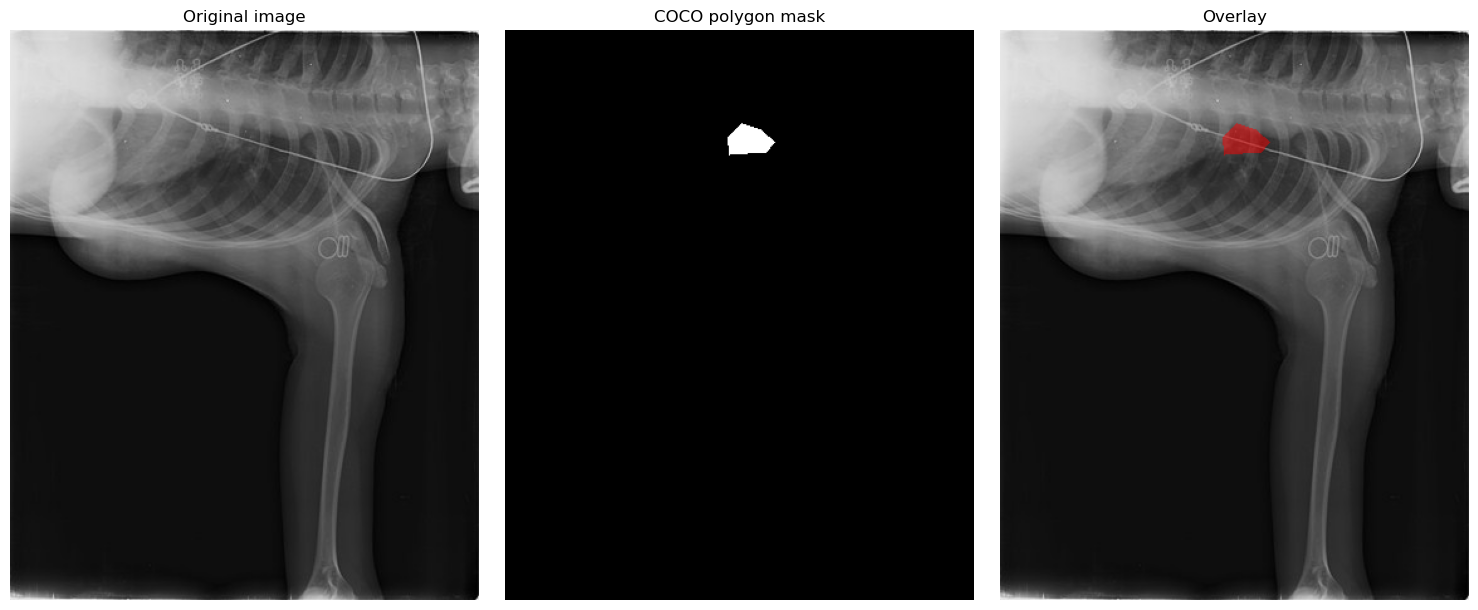

In [13]:
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import numpy as np

filename = "IMG0002628.jpg"
image_info = coco_images[filename]
image_path = image_paths[filename]

image = Image.open(image_path).convert("RGB")
ann_list = annotations_by_image[image_info["id"]]

# Draw the polygon using the coordinates exactly as stored in COCO
mask_image = Image.new("L", image.size, 0)
draw = ImageDraw.Draw(mask_image)

for ann in ann_list:
    for polygon in ann.get("segmentation", []):
        points = [
            (polygon[i], polygon[i + 1])
            for i in range(0, len(polygon), 2)
        ]
        if len(points) >= 3:
            draw.polygon(points, fill=255)

mask = np.array(mask_image)
overlay = np.array(image).copy()

# Tint annotated pixels red
overlay[mask > 0] = (
    0.5 * overlay[mask > 0] + 0.5 * np.array([255, 0, 0])
).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(15, 6))

axes[0].imshow(image)
axes[0].set_title("Original image")

axes[1].imshow(mask, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("COCO polygon mask")

axes[2].imshow(overlay)
axes[2].set_title("Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [15]:
# Exclude the image with inconsistent COCO dimensions
EXCLUDE_IMAGES = {"IMG0002628.jpg"}

df_filtered = df[~df["image_id"].isin(EXCLUDE_IMAGES)].copy()

# Keep only images that remain in the filtered dataset
image_paths_filtered = {
    name: path
    for name, path in image_paths.items()
    if name not in EXCLUDE_IMAGES
}

# Keep only valid masks
mask_df_filtered = mask_df[
    ~mask_df["image_id"].isin(EXCLUDE_IMAGES)
].copy()

print("Original CSV rows:", len(df))
print("Filtered CSV rows:", len(df_filtered))
print("Filtered image paths:", len(image_paths_filtered))
print("Valid masks:", len(mask_df_filtered))
print("Fracture-positive images:", int(df_filtered["fractured"].sum()))

Original CSV rows: 4083
Filtered CSV rows: 4082
Filtered image paths: 4082
Valid masks: 718
Fracture-positive images: 718


In [16]:
df_filtered.to_csv(PROCESSED_DIR / "dataset_filtered.csv", index=False)
mask_df_filtered.to_csv(PROCESSED_DIR / "mask_index.csv", index=False)

print("Filtered dataset files saved to:", PROCESSED_DIR)

Filtered dataset files saved to: c:\Users\rylee\OneDrive\UCF\Independent Study\Bone_Fracture_Segmentation\processed
